## UrbanCart

#### Business Problem
---
UrbanCart contracted me as a freelance machine learning engineer to solve a critical marketing bottleneck caused by their reliance on ineffective, "one-size-fits-all" campaigns. 

The marketing team strongly suspects that their database contains genuinely distinct shopper personalities, but they lack a predefined list of categories to sort them into and have no analytical way of knowing how many groups actually exist. Because the customer segments are completely unlabeled in advance, my task is to design an unsupervised learning pipeline using clustering algorithms to mathematically discover the natural structure within their customer transaction data. 

The ultimate goal is to translate these hidden data clusters into clear, distinct business profiles, enabling UrbanCart to replace their blanket messaging with precision-targeted, automated campaigns that speak directly to what motivates each specific kind of shopper to buy.

In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [3]:
data = pd.read_csv(r"C:\Users\HP\Desktop\TeSA\UrbanCart Customer Segmentation\milestone3-customer-segment.csv")
data.head()

,AvgOrderValue,PurchaseFrequency,NumProductCategoriesShoppedIn,AvgDiscountUsed
0,23.84,1.28,1,0.020
1,185.29,1.94,2,0.017
2,40.77,2.30,2,0.285
3,43.39,4.22,2,0.402
4,28.85,11.21,4,0.076


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   AvgOrderValue                  20000 non-null  float64
 1   PurchaseFrequency              20000 non-null  float64
 2   NumProductCategoriesShoppedIn  20000 non-null  int64  
 3   AvgDiscountUsed                20000 non-null  float64
dtypes: float64(3), int64(1)
memory usage: 625.1 KB


In [7]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
AvgOrderValue,20000.0,84.768276,76.786301,5.0,31.510,42.700,168.345,305.240
PurchaseFrequency,20000.0,5.064727,4.773541,0.2,1.710,2.700,9.480,21.960
NumProductCategoriesShoppedIn,20000.0,2.155900,0.907654,1.0,2.000,2.000,3.000,7.000
AvgDiscountUsed,20000.0,0.136403,0.135263,0.0,0.039,0.081,0.198,0.602


### Data Dictionary (What do the features in the dataset mean?)
---
- `AvgOrderValue`: The average amount of money a customer spends each time they place an order.
- `PurchaseFrequency`: How often a customer buys from your business within a specific timeframe (quarterly).
- `NumProductCategoriesShoppedIn`: The variety of different product types or departments a customer has bought from (e.g., "Electronics," "Apparel," and "Home Goods").
- `AvgDiscountUsed`: The average percentage or dollar amount of discounts, coupons, or promo codes a customer applies to their purchases.

In [9]:
data.columns

Index(['AvgOrderValue', 'PurchaseFrequency', 'NumProductCategoriesShoppedIn',
       'AvgDiscountUsed'],
      dtype='str')

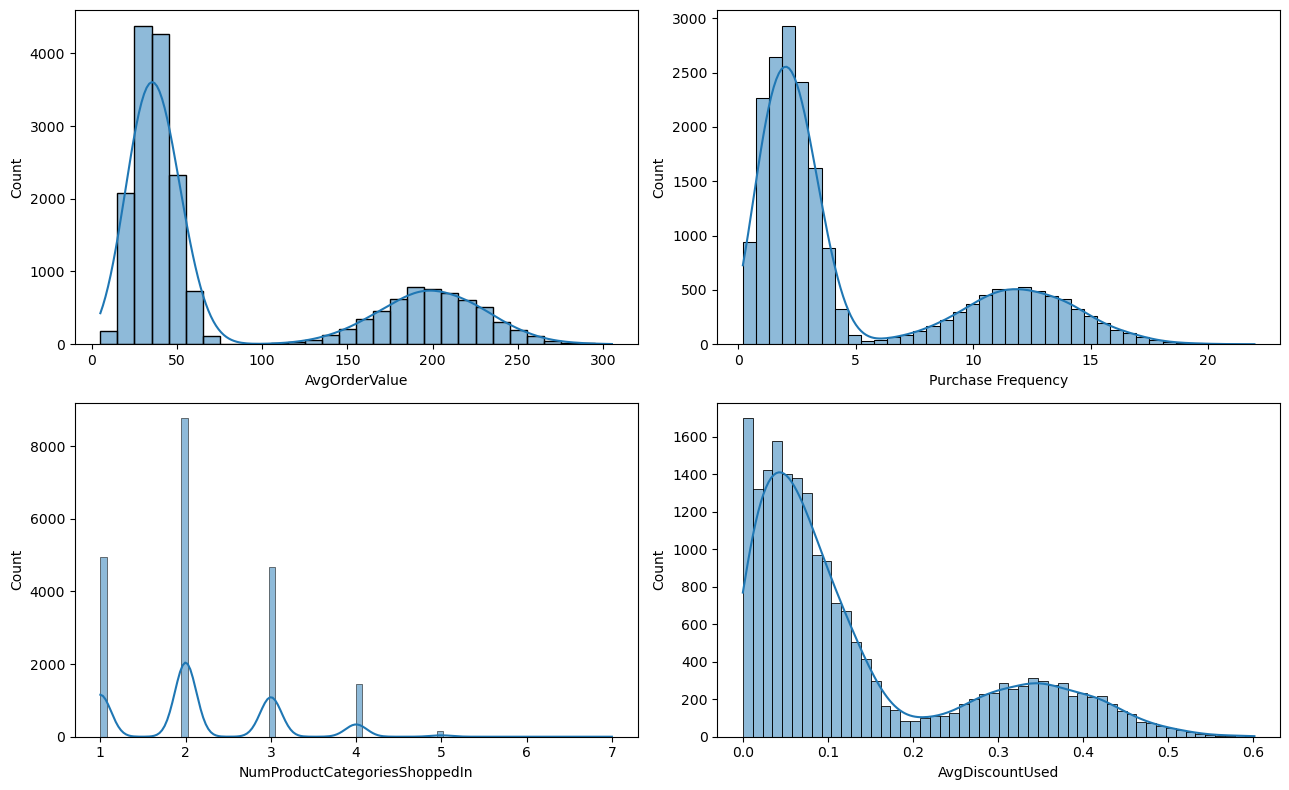

In [13]:
# Visualize data dustribution
fig, axes = plt.subplots(2,2,figsize=(13,8))

sns.histplot(data["AvgOrderValue"],kde=True,ax=axes[0,0])
axes[0,0].set_xlabel("AvgOrderValue")

sns.histplot(data["PurchaseFrequency"],kde=True,ax=axes[0,1])
axes[0,1].set_xlabel("Purchase Frequency")

sns.histplot(data["NumProductCategoriesShoppedIn"],kde=True,ax=axes[1,0])
axes[1,0].set_xlabel("NumProductCategoriesShoppedIn")

sns.histplot(data["AvgDiscountUsed"],kde=True,ax=axes[1,1])
axes[1,1].set_xlabel("AvgDiscountUsed")

plt.tight_layout()
plt.show()

**Insights**

Using the distribution plots above, we can clearly observe that the customer base splits into two distinct behavioral categories.

- The average order value highlights two separate spending tiers; one set of customers typically spends between `$10` and `$80`, with a major spike concentrated around `$20` - `$40`, while the higher-tier segment spends heavily between `$120` and `$260`, peaking around `$180` - `$220`.
- The purchase frequency distribution reveals a stark contrast in engagement; a low-frequency segment rarely purchases, averaging just 2 - 3 transactions over the three-month period, whereas a highly active segment of frequent buyers completes 10 - 15 purchases in the same timeframe.
- The average discount used feature highlights clear differences in price sensitivity; one group of full-price buyers rarely utilizes promotions, keeping their discount usage near zero (0% - 10%), while a highly price-sensitive cohort relies heavily on deals, centering their purchases around a 30% - 40% discount range.
- The number of product categories shopped behaves differently from the other features, as it does not separate the audience into two distinct groups; instead, the plot reveals a unified cross-shopping constraint, showing that the overwhelming majority of all customers restrict their purchases to exactly two product categories

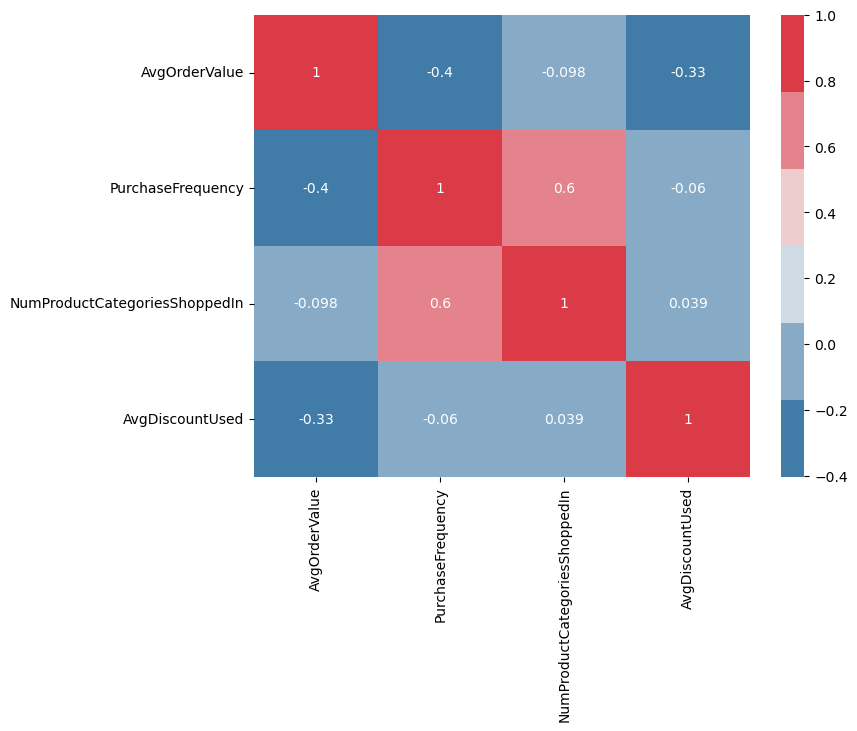

In [25]:
#correlation analysis
plt.figure(figsize=(8,6))
sns.heatmap(data=data.corr(),annot=True, cbar=True, cmap=sns.diverging_palette(240,10))
plt.show()

**Insights**

The heatmap shows correlations between the four behavioral features. PurchaseFrequency and NumProductCategoriesShoppedIn show a moderate positive correlation (0.6), which is worth flagging since K-means doesn't handle highly correlated features well, redundant dimensions get implicitly double-weighted in the Euclidean distance calculation, which can bias the resulting clusters.

That said, this correlation isn't severe enough to justify dropping a feature outright. NumProductCategoriesShoppedIn also carries distinct behavioral signal. It captures the breadth of a customer's purchasing habits, which is conceptually different from how *often* they purchase, even if the two tend to move together. Given the low dimensionality of the dataset (only four features), discarding one would sacrifice more information than the redundancy actually justifies. Both features will therefore be retained for clustering.

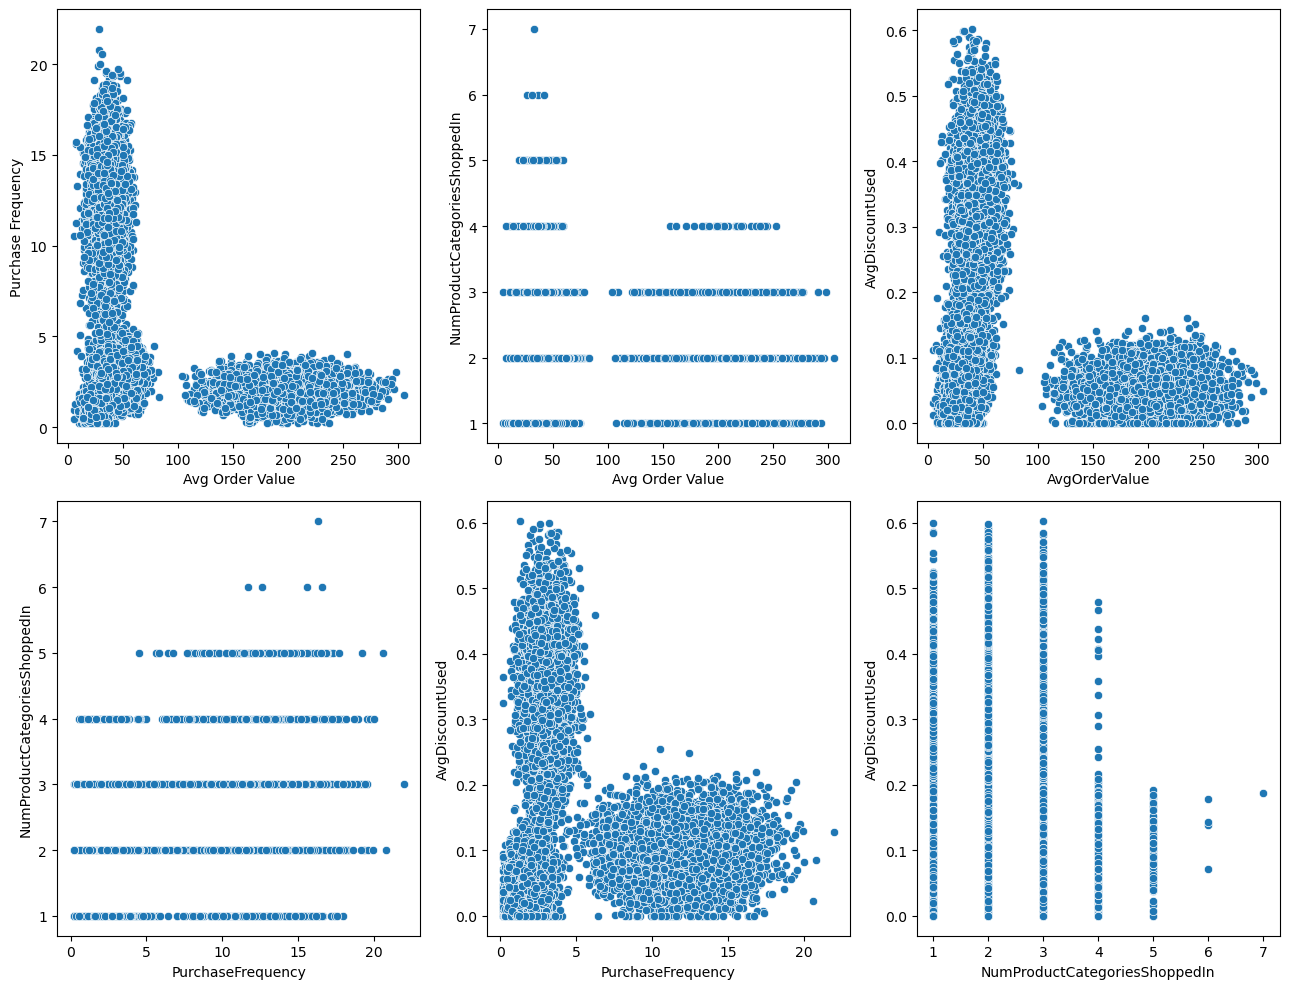

In [23]:
# Visualize correlations between features
fig, axes = plt.subplots(2,3,figsize=(13,10))

sns.scatterplot(x="AvgOrderValue", y="PurchaseFrequency", data=data, ax=axes[0,0])
axes[0,0].set_xlabel("Avg Order Value")
axes[0,0].set_ylabel("Purchase Frequency")

sns.scatterplot(x="AvgOrderValue", y="NumProductCategoriesShoppedIn", data=data,ax=axes[0,1])
axes[0,1].set_xlabel("Avg Order Value")
axes[0,1].set_ylabel("NumProductCategoriesShoppedIn")

sns.scatterplot(x="AvgOrderValue", y="AvgDiscountUsed", data=data,ax=axes[0,2])
axes[0,2].set_xlabel("AvgOrderValue")
axes[0,2].set_ylabel("AvgDiscountUsed")

sns.scatterplot(x="PurchaseFrequency", y="NumProductCategoriesShoppedIn", data=data,ax=axes[1,0])
axes[1,0].set_xlabel("PurchaseFrequency")
axes[1,0].set_ylabel("NumProductCategoriesShoppedIn")

sns.scatterplot(x="PurchaseFrequency", y="AvgDiscountUsed", data=data,ax=axes[1,1])
axes[1,1].set_xlabel("PurchaseFrequency")
axes[1,1].set_ylabel("AvgDiscountUsed")

sns.scatterplot(x="NumProductCategoriesShoppedIn", y="AvgDiscountUsed", data=data,ax=axes[1,2])
axes[1,2].set_xlabel("NumProductCategoriesShoppedIn")
axes[1,2].set_ylabel("AvgDiscountUsed")

plt.tight_layout()
plt.show()

The dominant pattern is a clean two-group split driven by **AvgOrderValue**, visible in every plot that includes it

1. **Low AvgOrderValue (~0–90), high engagement group:** Buys frequently (Purchase Frequency mostly 5–20), uses discounts heavily (AvgDiscountUsed 0.1–0.6). This looks like price-sensitive, high-frequency shoppers, possibly deal-hunters or bargain buyers making frequent small purchases.

2. **High AvgOrderValue (~100–300), low engagement group:** Buys infrequently (mostly 0–5), uses very few discounts (mostly <0.15). This looks like occasional big-ticket buyers who pay closer to full price.

There's a visible **gap between ~90 and ~100 in AvgOrderValue** with almost no data points. This means AvgOrderValue isn't a continuous spectrum; it's genuinely bimodal. 

Looking at the `NumCategoriesShoppedIn` vs `PurchaseFrequency` Plot, if you pick any purchase frequency value, customers there aren't all shopping the same number of categories; they're spread across several different values. So knowing how often someone buys doesn't reliably tell you how many categories they buy from. The two features move together somewhat, but not enough that one is just a stand-in for the other (because being correlated mean you can mostly get the same information from both); each still adds information the other one misses. This finding further corroborates why both features will be used for clustering instead of dropping one.

### Data Preprocessing
---

After checking for duplicates and missing values, the next step is to standardize (Standard Scaling) the features before training the unsupervised model (whether K-means or hierarchical clustering). This is necessary because both models rely on Euclidean distance to measure similarity between data points. A feature with a large numeric range would dominate that distance calculation, causing the model to assign data points to the wrong cluster simply because one feature's scale outweighs the others. Standard scaling puts all features on a comparable scale (mean 0, standard deviation 1), ensuring each feature contributes proportionally to the distance calculation rather than being skewed by its original units or magnitude.

From the distribution plots, `AvgOrderValue`, `PurchaseFrequency`, and `AvgDiscountUsed` might initially look skewed, but they are actually bimodal. Each shows two distinct peaks rather than a single tail trailing off. Log-transformation is a technique meant to correct right-skew by compressing a long tail, and applying it here would not fix the bimodality. Instead, it would compress the x-axis and risk merging the two modes together or distorting the gap between them, which is exactly the separation the model needs to detect these segments.

Therefore, for preprocessing, only standardization (Standard Scaling) will be applied.

In [34]:
df = data.copy()

In [36]:
#Check for duplicates
df.duplicated().sum()

0

In [38]:
df.isna().sum()

AvgOrderValue                    0
PurchaseFrequency                0
NumProductCategoriesShoppedIn    0
AvgDiscountUsed                  0
dtype: int64

In [40]:
# Apply Standard Scaling to all Features
feature_scaler = StandardScaler()
df = pd.DataFrame(feature_scaler.fit_transform(df), columns=df.columns, index=df.index)
df.head()

,AvgOrderValue,PurchaseFrequency,NumProductCategoriesShoppedIn,AvgDiscountUsed
0,-0.793498,-0.792875,-1.273534,-0.860588
1,1.309143,-0.654609,-0.171766,-0.882768
2,-0.573011,-0.579192,-0.171766,1.098602
3,-0.538889,-0.176965,-0.171766,1.963602
4,-0.728251,1.287394,2.031771,-0.446571


### Model Development
---

I selected K-Means clustering over Hierarchical Clustering for this project based on two primary factors: 

**Prior structural insight and computational efficiency**.

Prior Intuition and Optimization: Exploratory data analysis already provides a strong initial indication of the underlying cluster structure. K-Means is perfectly suited for this scenario because it allows me to define a targeted search range and programmatically optimize for the exact number of segments using evaluation metrics (such as the Elbow Method or Silhouette Score). Conversely, hierarchical clustering is better reserved for exploratory scenarios where there is absolutely no preconception of the cluster count.

Computational Scaling and Resources: The dataset is relatively large, which favors the linear scalability of K-Means. In contrast, agglomerative hierarchical clustering (the most common type of hierarchical clustering) utilizes a bottom-up approach that treats every individual data point as its own initial cluster. Because it must iteratively calculate and store a massive distance matrix between all pairs of data points, it requires significant compute time and memory resource overhead—making it highly inefficient for a dataset of this size.

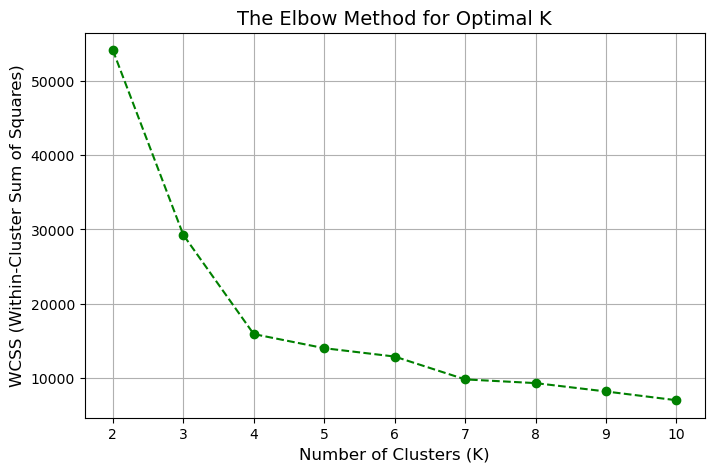

In [71]:
# use the elbow method to optimize for the different value of K
wcss = []
k_range = range(2,11)

for k in k_range:
    # 'kmeans_plusplus' ensures stable, optimal cluster center initialization
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=1)
    kmeans.fit(df)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method Graph
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker="o", linestyle="--", color="g")
plt.title("The Elbow Method for Optimal K", fontsize=14)
plt.xlabel("Number of Clusters (K)", fontsize=12)
plt.ylabel("WCSS (Within-Cluster Sum of Squares)", fontsize=12)
plt.xticks(k_range)
plt.grid(True)
plt.show()

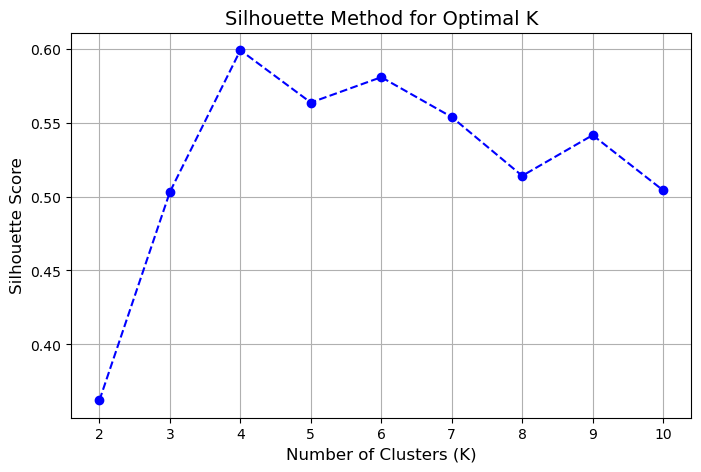

For K = 2, Silhouette Score is: 0.3623
For K = 3, Silhouette Score is: 0.5031
For K = 4, Silhouette Score is: 0.5989
For K = 5, Silhouette Score is: 0.5635
For K = 6, Silhouette Score is: 0.5806
For K = 7, Silhouette Score is: 0.5537
For K = 8, Silhouette Score is: 0.5140
For K = 9, Silhouette Score is: 0.5415
For K = 10, Silhouette Score is: 0.5042


In [73]:
# use the silhoutte method to optimize for the different value of K

silhouette_k_range = range(2, 11)
silhouette_scores = []

for k in silhouette_k_range:
    s_kmeans = KMeans(n_clusters=k, init="k-means++", random_state=1)
    cluster_labels = s_kmeans.fit_predict(df)

    # Calculate the average silhouette score for all samples
    score = silhouette_score(df, cluster_labels)
    silhouette_scores.append(score)

# Plot the Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(silhouette_k_range, silhouette_scores, marker="o", linestyle="--", color="b")
plt.title("Silhouette Method for Optimal K", fontsize=14)
plt.xlabel("Number of Clusters (K)", fontsize=12)
plt.ylabel("Silhouette Score", fontsize=12)
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Print the exact scores
for k, score in zip(silhouette_k_range, silhouette_scores):
    print(f"For K = {k}, Silhouette Score is: {score:.4f}")

Using both elbow and silhouette method, Kmeans was able to identify 4 as the optimal number of clusters for this data

In [146]:
new_df = df.copy()

In [148]:
#Train KMeans with K = 4

kmeans_model = KMeans(n_clusters=4, random_state=1, init="k-means++")
customer_clusters = kmeans_model.fit_predict(new_df)
new_df["customer_clusters"] = customer_clusters

In [150]:
new_df.head()

,AvgOrderValue,PurchaseFrequency,NumProductCategoriesShoppedIn,AvgDiscountUsed,customer_clusters
0,-0.793498,-0.792875,-1.273534,-0.860588,1
1,1.309143,-0.654609,-0.171766,-0.882768,0
2,-0.573011,-0.579192,-0.171766,1.098602,3
3,-0.538889,-0.176965,-0.171766,1.963602,3
4,-0.728251,1.287394,2.031771,-0.446571,2


In [152]:
#Assign the customer clusters back to the original data

new_data = data.copy()
new_data["customer_clusters"] = kmeans_model.labels_
new_data.head()

,AvgOrderValue,PurchaseFrequency,NumProductCategoriesShoppedIn,AvgDiscountUsed,customer_clusters
0,23.84,1.28,1,0.020,1
1,185.29,1.94,2,0.017,0
2,40.77,2.30,2,0.285,3
3,43.39,4.22,2,0.402,3
4,28.85,11.21,4,0.076,2


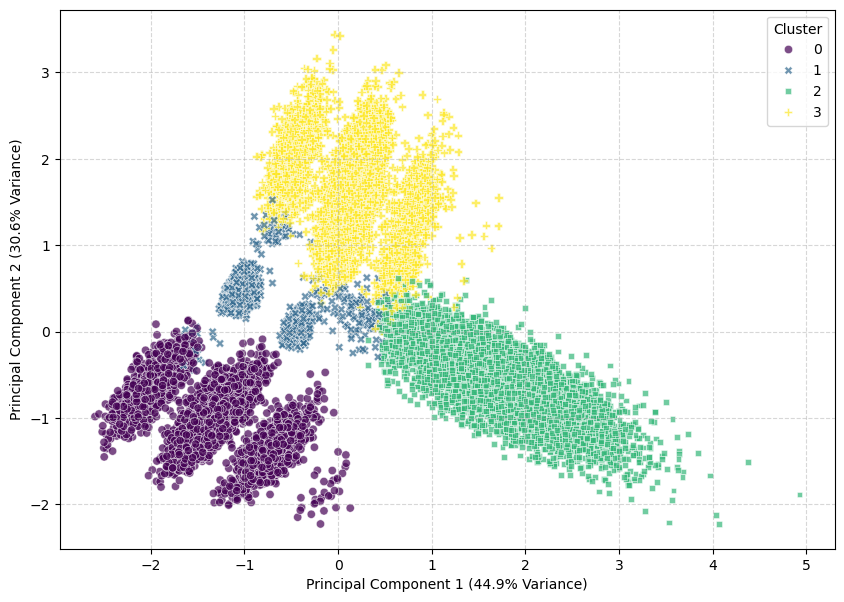

In [154]:
# Initialize PCA to reduce data to 2 dimensions
pca = PCA(n_components=2, random_state=1)

# Fit and transform the features (excluding the cluster column itself)
# We drop 'customer_clusters' so it isn't treated as a feature during PCA
features_to_reduce = new_df.drop(columns=["customer_clusters"])
pca_features = pca.fit_transform(features_to_reduce)

# Add the PCA coordinates back to the DataFrame for easy plotting
new_df["pca_x"] = pca_features[:, 0]
new_df["pca_y"] = pca_features[:, 1]

# Create the 2D scatter plot
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x="pca_x",
    y="pca_y",
    hue="customer_clusters",
    data=new_df,
    palette="viridis",  # Color palette for the 4 clusters
    style="customer_clusters",  # Optional: different markers for each cluster
    alpha=0.7,
)

# Add titles and labels
#plt.title("Customer Clusters Visualized in 2D (PCA)", fontsize=14)
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")
plt.legend(title="Cluster")
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

In [156]:
new_df["customer_clusters"].value_counts().sort_index()

customer_clusters
0    5898
1    3242
2    5803
3    5057
Name: count, dtype: int64

**Insight**

UrbanCart's marketing team wants to understand what kind of customers they have, specifically, their shopping habits. The four features in the dataset give strong signals about different customer types. So Kmeans was built using all four features to group customers accurately.

Since there are four features, we can't plot the clusters directly on a normal 2D chart. To make the groups visible, I compressed the data down to two dimensions using Principal component analysis (PCA). This 2D plot captures about 75% of the real differences between customers, so it's a good picture of the overall groupings, even though some finer detail is lost in the simplification.

---

The chart shows four customer groups. The purple group stands out as clearly different from the others. These customers behave quite differently from the rest, especially in how they rank on the horizontal axis of the map.

Also the purple, blue, and yellow groups form thin diagonal "stripes" rather than one solid blob. This pattern usually shows up when customers are being separated by a feature with only a few possible values like the `NumProductCategoriesShoppedIn` (which contains discrete values representing the number of product category a customer order comprises of), rather than a smooth range like spending amount.

### What do these different Clusters Mean?
---

In [164]:
# Group by cluster and get mean of each original feature
cluster_profile = new_data.groupby("customer_clusters")[features_to_reduce.columns.tolist()].mean()

# Add overall average as a reference row
cluster_profile.loc["Overall"] =  new_data[["AvgOrderValue", "PurchaseFrequency", "NumProductCategoriesShoppedIn", "AvgDiscountUsed"]].mean()

cluster_profile.round(2)

,AvgOrderValue,PurchaseFrequency,NumProductCategoriesShoppedIn,AvgDiscountUsed
customer_clusters,,,,
0,199.81,2.01,1.99,0.05
1,26.38,1.31,1.12,0.03
2,35.15,12.07,3.03,0.10
3,44.97,3.00,2.01,0.35
Overall,84.77,5.06,2.16,0.14


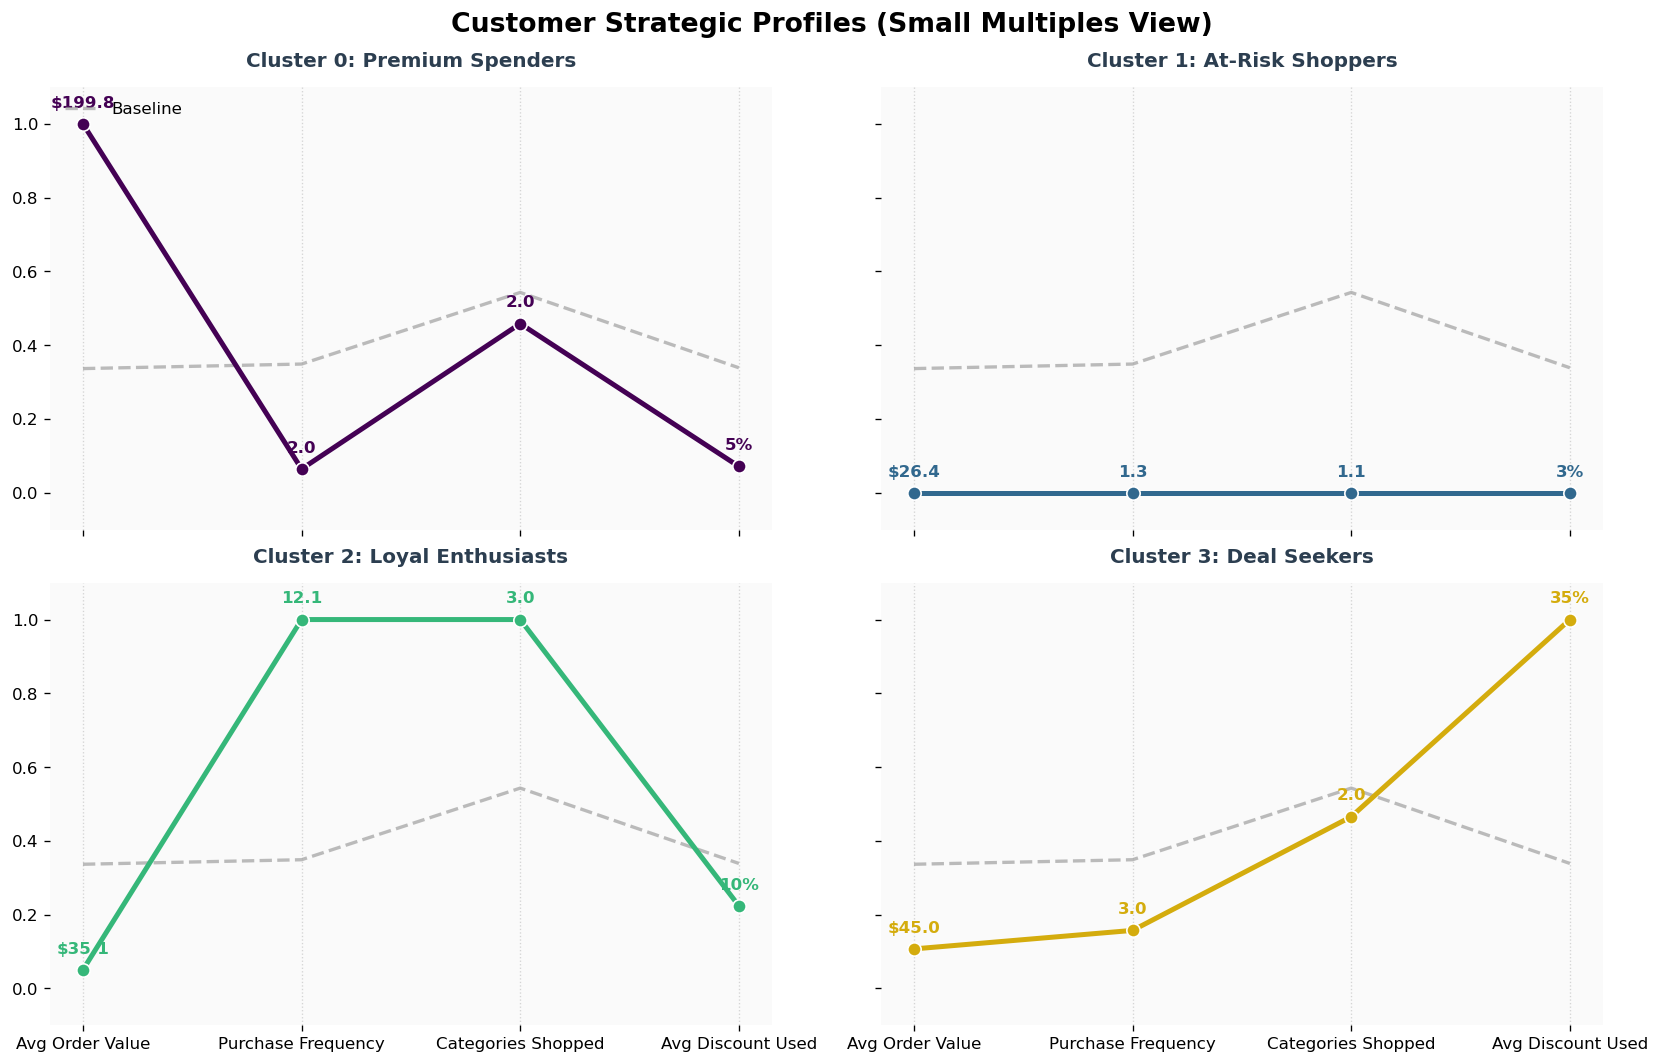

In [178]:
features = [
    "Avg Order Value",
    "Purchase Frequency",
    "Categories Shopped",
    "Avg Discount Used",
]
cluster_names = [
    "Cluster 0: Premium Spenders",
    "Cluster 1: At-Risk Shoppers",
    "Cluster 2: Loyal Enthusiasts",
    "Cluster 3: Deal Seekers",
]
colors = ["#440154", "#31688E", "#35B779", "#D4AC0D"] 

matrix_data = cluster_profile.loc[0:3, [
    "AvgOrderValue", "PurchaseFrequency", "NumProductCategoriesShoppedIn", "AvgDiscountUsed"
]].values
overall_data = cluster_profile.loc["Overall", [
    "AvgOrderValue", "PurchaseFrequency", "NumProductCategoriesShoppedIn", "AvgDiscountUsed"
]].values

# Normalize strictly for visual alignment across different scales
min_vals = cluster_profile.iloc[0:5].min().values
max_vals = cluster_profile.iloc[0:5].max().values
norm_matrix = (matrix_data - min_vals) / (max_vals - min_vals)
norm_overall = (overall_data - min_vals) / (max_vals - min_vals)

x_indices = np.arange(len(features))

# Initialize a 2x2 grid of clean subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 9), dpi=120, sharex=True, sharey=True)
axes = axes.flatten()

# Populate each subplot
for i, ax in enumerate(axes):
    ax.set_facecolor("#fafafa") 
    
    # Plot the baseline in the background
    ax.plot(
        x_indices, norm_overall, linestyle="--", linewidth=2, color="#a0a0a0", alpha=0.7, label="Baseline"
    )
    
    # Plot the specific cluster line
    ax.plot(
        x_indices, norm_matrix[i], marker="o", linewidth=3, markersize=8, color=colors[i], markeredgecolor="w"
    )
    
    # Add clean, non-overlapping annotations for the real values
    for x_idx, real_val in enumerate(matrix_data[i]):
        if x_idx == 0:
            label = f"${real_val:.1f}"
        elif x_idx == 3:
            label = f"{real_val*100:.0f}%"
        else:
            label = f"{real_val:.1f}"
            
        ax.annotate(
            label,
            (x_idx, norm_matrix[i, x_idx]),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center",
            fontsize=10,
            fontweight="bold",
            color=colors[i]
        )
        
    # Styling details per window
    ax.set_title(cluster_names[i], fontsize=12, fontweight="bold", pad=12, color="#2c3e50")
    ax.set_xticks(x_indices)
    ax.set_xticklabels(features, fontsize=10)
    ax.set_ylim(-0.1, 1.1)
    ax.grid(True, axis="x", linestyle=":", alpha=0.5)
    
    # Remove unnecessary border spines
    for spine in ["top", "right", "left", "bottom"]:
        ax.spines[spine].set_visible(False)

# Add a single unified baseline legend at the top
axes[0].legend(loc="upper left", frameon=False, fontsize=10)

plt.suptitle("Customer Strategic Profiles (Small Multiples View)", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


By evaluating the customer base across four features: `AvgOrderValue`, `PurchaseFrequency`, `NumProductCategoriesShoppedIn`, `AvgDiscountUsed`, I have identified four distinct customer personas. Using the typical customer (UrbanCart Baseline) as a benchmark, the marketing team can clearly see where to cut wasted marketing spend and where to drive high-margin growth.

#### Cluster 0: Premium Spenders (High-Value VIPs)

This group drives an extraordinary `Average Order Value` of `$199.81`, which is well over double UrbanCart baseline `$84.77`. However, they visit only 2 times every quarter and have a microscopic discount reliance of just 5%. This is the company's most profitable segment per transaction. They are completely unaffected by sales or coupons; they buy strictly based on quality, brand prestige, or immediate need. 

**Action Plan/Recommendation: Stop sending them discounts. Giving coupons to this group actively burns UrbanCart profit margin. Instead, target them with premium product lines, exclusive early-access collections, and white-glove customer service.**

#### Cluster 2: Loyal Enthusiasts (The Growth Engine)

This cluster is defined by an incredible `Purchase Frequency` of 12.07 visits which is more than double the average customer baseline (5.06). They also exhibit the highest cross-shopping behavior, buying across 3+ distinct product categories. These are the company's core brand champions. They love the company's ecosystem and treat shopping with UrbanCart as a routine habit. While their average basket size is lower `$35.15`, their consistent, predictable return rate makes them the financial backbone of UrbanCart steady revenue.

**Action Plan/Recommendation: Capitalize on their willingness to cross-shop. Target them with personalized product recommendations from categories they haven't tried yet, and lock them in deeper with a structured customer loyalty rewards program.**

#### Cluster 3: Deal Seekers (Promotion Driven)

This group hovers near the baseline for spend `$44.97` and frequency (3.00), but spikes aggressively on Avg Discount Used at 35%, which is 2.5 times higher than the company baseline (14%). These customers are strictly motivated by margin-cutting events. They rarely buy anything at full price and will actively hold out on purchases until a clearance sale or discount code lands in their inbox.

**Action Plan/Recommendation: Use them strategically to clear inventory. Target them heavily during flash sales, end-of-season warehouse clearances, or use volume-based incentives (e.g., "Spend `$60` to unlock this 35% discount") to forcefully pull up their transaction size.**

#### Cluster 1: At-Risk Shoppers (Low-Engagement)

This segment sits flatly at the bottom of the chart, scoring drastically below the baseline on every single metric (Spend: `$26.38` vs `$84.77`; Frequency: 1.31 vs 5.06). These are "one-and-done" test buyers who either had a forgettable experience or have completely disengaged from UrbanCart. They represent stagnant data and are on the verge of churning entirely.

**Action Plan/Recommendation: Deploy low-cost, automated win-back email sequences. Since their current value is minimal, we should not allocate heavy manual ad spend here; instead, use automated triggers offering a strong "come back" incentive to see if they can be moved into a more active cluster.**

In [184]:
import joblib
joblib.dump(kmeans_model, "segment_model.pkl")
print("Model Saved Successfully!")

Model Saved Successfully!
